<a href="https://colab.research.google.com/github/anderafryanto-dotcom/Graphitic-Domain-Biochar-Machine-Learning/blob/main/Note_1_Exploratory_Spectral_Analysis_of_Biochar_FTIR_and_Raman_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

import seaborn as sns

from scipy import stats

from sklearn.preprocessing import StandardScaler

from sklearn.decomposition import PCA

In [2]:
# ==========================
# Load Dataset
# ==========================

df = pd.read_excel("Data Collection of Biochar ML.xlsx")

print(df.shape)

df.head()

(486, 6860)


,sample_id,biomass,temp,replicate,y_idig,peak_OH,peak_CC_1600,peak_CO_1700,peak_CO_1050,peak_CH_2920,...,ftir_3995.951,ftir_3996.434,ftir_3996.916,ftir_3997.398,ftir_3997.88,ftir_3998.362,ftir_3998.844,ftir_3999.326,ftir_3999.809,ftir_4000.291
0,200_1,Sugar-apple Seed,200,1,0.886520,5.907780,2.567610,14.465640,1.384130,0.216640,...,0.000615,0.000544,0.000470,0.000395,0.000319,0.000241,0.000161,0.000080,-0.000003,-0.000088
1,200_1,Sugar-apple Seed,200,2,0.851280,5.510390,2.693430,16.649050,1.466970,0.253510,...,0.000661,0.000576,0.000488,0.000399,0.000308,0.000214,0.000119,0.000021,-0.000078,-0.000180
2,200_2,Sugar-apple Seed,200,3,0.892340,5.907780,2.567610,14.465640,1.384130,0.216640,...,0.000093,0.000054,0.000015,-0.000025,-0.000066,-0.000107,-0.000149,-0.000191,-0.000234,-0.000278
3,200_4,Sugar-apple Seed,200,4,0.882533,6.206852,2.474513,14.526912,1.349543,0.204830,...,0.000569,0.000541,0.000480,0.000375,0.000321,0.000243,0.000160,0.000080,-0.000003,-0.000091
4,200_5,Sugar-apple Seed,200,5,0.885443,5.865407,2.514734,14.461602,1.446849,0.209381,...,0.000609,0.000572,0.000477,0.000420,0.000319,0.000245,0.000161,0.000083,-0.000003,-0.000088


In [3]:
print("="*60)
print("Dataset Overview")
print("="*60)

print(df.info())

print("\n")

display(df.describe(include='all'))

Dataset Overview
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 486 entries, 0 to 485
Columns: 6860 entries, sample_id to ftir_4000.291
dtypes: float64(6856), int64(2), object(2)
memory usage: 25.4+ MB
None




,sample_id,biomass,temp,replicate,y_idig,peak_OH,peak_CC_1600,peak_CO_1700,peak_CO_1050,peak_CH_2920,...,ftir_3995.951,ftir_3996.434,ftir_3996.916,ftir_3997.398,ftir_3997.88,ftir_3998.362,ftir_3998.844,ftir_3999.326,ftir_3999.809,ftir_4000.291
count,486,486,486.000000,486.000000,486.000000,486.000000,486.000000,486.000000,486.000000,486.000000,...,486.000000,486.000000,4.860000e+02,4.860000e+02,486.000000,486.000000,486.000000,486.000000,486.000000,486.000000
unique,81,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,200_1,Sugar-apple Seed,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,7,81,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,600.000000,5.000000,1.065465,2.596613,4.130845,6.287273,0.734346,0.894889,...,0.000591,0.000529,4.608552e-04,3.908940e-04,0.000323,0.000249,0.000173,0.000095,0.000017,-0.000064
std,NaN,NaN,258.464937,2.584649,0.159867,2.819558,5.432306,5.012206,0.835930,0.866077,...,0.000975,0.000892,7.921628e-04,6.936199e-04,0.000601,0.000508,0.000427,0.000370,0.000338,0.000346
min,NaN,NaN,200.000000,1.000000,0.808730,0.143804,0.045459,0.101412,0.013340,0.046058,...,-0.000937,-0.001030,-1.180000e-03,-1.366127e-03,-0.001545,-0.001715,-0.001882,-0.002071,-0.002265,-0.002400
25%,NaN,NaN,400.000000,3.000000,0.962641,0.926965,0.760739,1.596222,0.118697,0.307123,...,0.000005,0.000005,6.782264e-07,3.740985e-07,-0.000002,-0.000005,-0.000005,-0.000004,-0.000010,-0.000058
50%,NaN,NaN,600.000000,5.000000,1.046205,1.444895,1.940646,4.946107,0.442489,0.620013,...,0.000215,0.000203,1.574898e-04,1.453509e-04,0.000125,0.000101,0.000074,0.000041,0.000006,-0.000006
75%,NaN,NaN,800.000000,7.000000,1.121000,3.007913,5.281437,9.961607,1.045357,1.114728,...,0.000834,0.000737,6.455538e-04,5.753036e-04,0.000502,0.000389,0.000320,0.000186,0.000084,0.000006


In [4]:
missing = df.isnull().sum()

missing = missing[missing>0]

missing.sort_values(ascending=False)

,0


In [5]:
duplicate = df.duplicated().sum()

print("Duplicate rows :", duplicate)

Duplicate rows : 0


In [6]:
print(df['biomass'].value_counts())

print(df['temp'].value_counts())

biomass
Sugar-apple Seed      81
Corncob               81
Bittermelon Leaves    81
Castor Seed           81
Sappanwood            81
Palm Kernel Meal      81
Name: count, dtype: int64
temp
200     54
300     54
400     54
500     54
600     54
700     54
800     54
900     54
1000    54
Name: count, dtype: int64


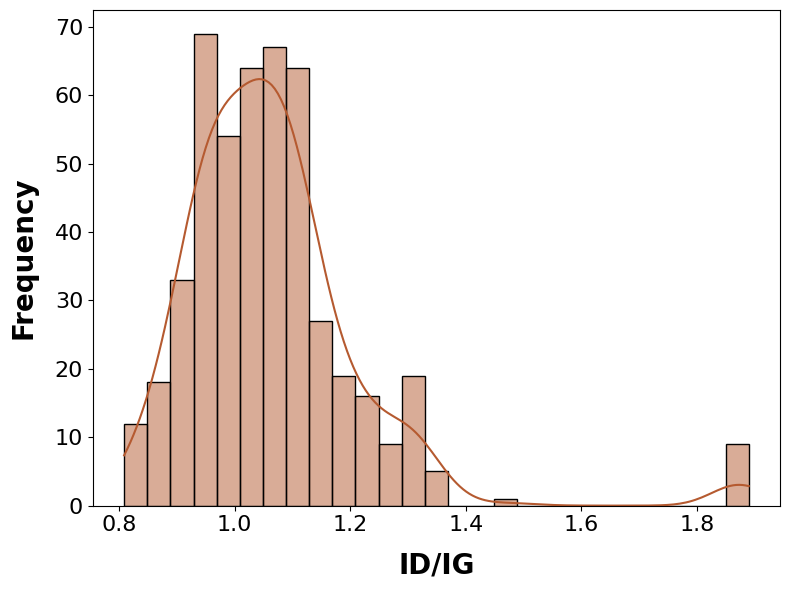

In [7]:
plt.figure(figsize=(8,6))

sns.histplot(df['y_idig'],
             kde=True,
             color='#b55a30')  # Maple brown/orange

plt.xlabel("ID/IG", fontsize=20, fontweight='bold', labelpad=12)
plt.ylabel("Frequency", fontsize=20, fontweight='bold', labelpad=12)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

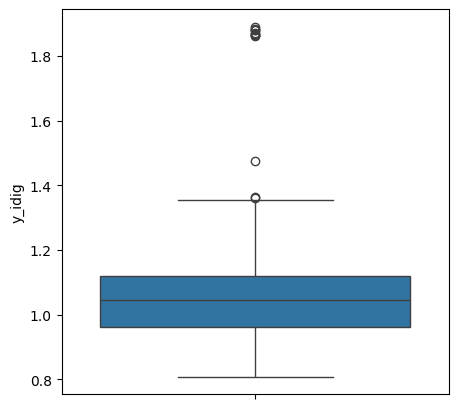

In [8]:
plt.figure(figsize=(5,5))

sns.boxplot(y=df['y_idig'])

plt.show()

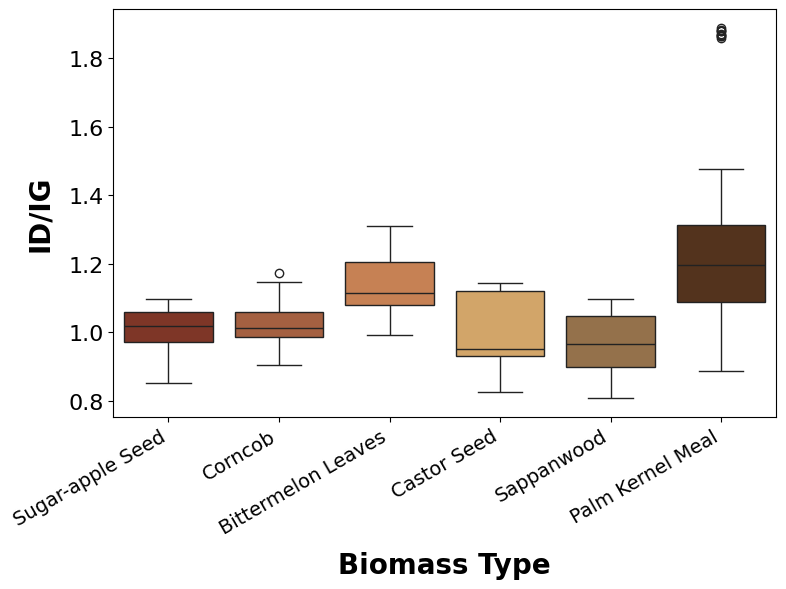

In [9]:
plt.figure(figsize=(8,6))

# Custom maple theme palette for 6 biomass types
maple_biomass_palette = ['#8c2d19', '#b55a30', '#d97d41', '#e3a857', '#a0713f', '#5c3214']

sns.boxplot(
    x='biomass',
    y='y_idig',
    data=df,
    palette=maple_biomass_palette
)

plt.xlabel("Biomass Type", fontsize=20,  fontweight='bold', labelpad=10)
plt.ylabel("ID/IG", fontsize=20, fontweight='bold', labelpad=10)
plt.xticks(rotation=30, ha='right', fontsize=14)  # Rotated & aligned to prevent overlapping
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

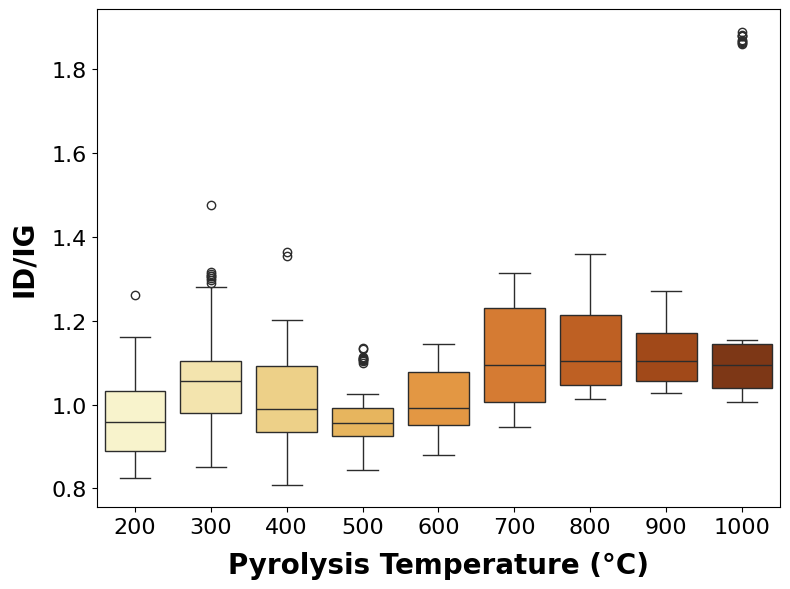

In [10]:
plt.figure(figsize=(8,6))

# Sequential maple palette for 9 temperatures
maple_temp_palette = sns.color_palette("YlOrBr", 9)

sns.boxplot(
    x='temp',
    y='y_idig',
    data=df,
    palette=maple_temp_palette
)

plt.xlabel("Pyrolysis Temperature (°C)", fontsize=20, fontweight='bold', labelpad=10)
plt.ylabel("ID/IG", fontsize=20, fontweight='bold', labelpad=10)
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.tight_layout()
plt.show()

Total FTIR variables : 6847


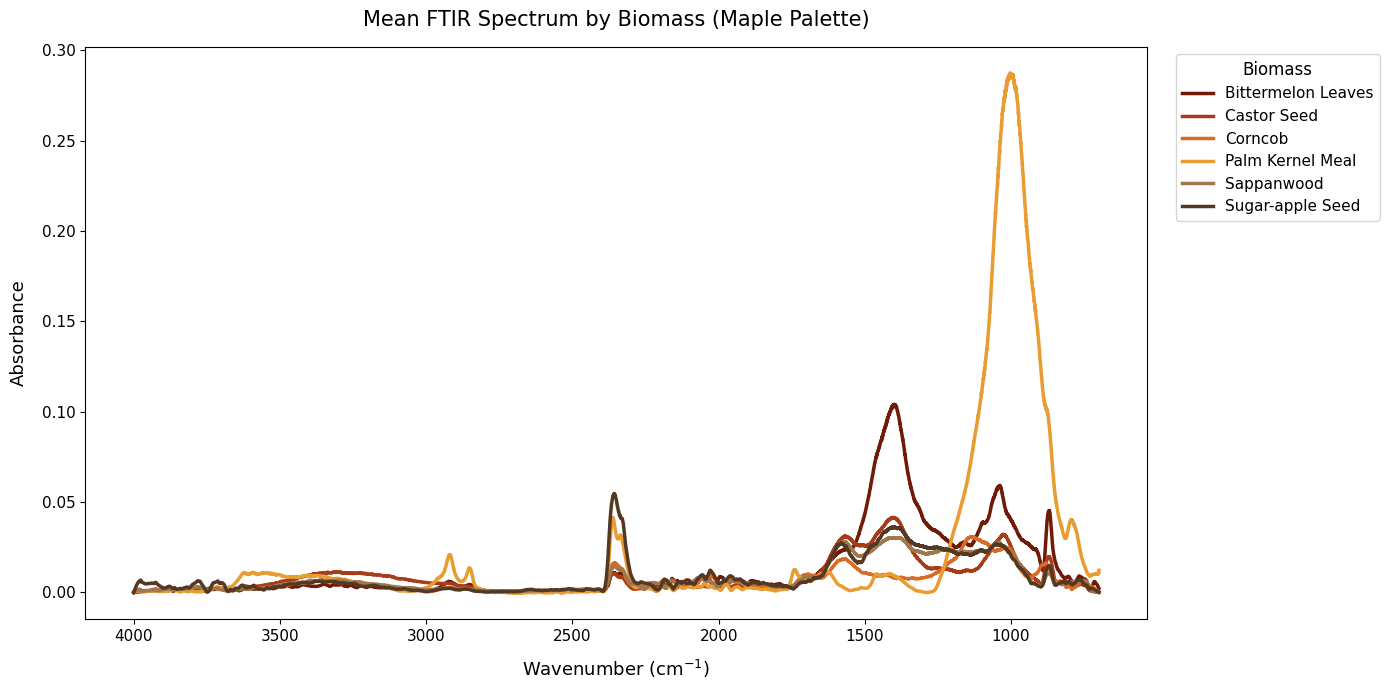

In [11]:
# ==========================================================
# PART 13. Mean FTIR Spectrum for Each Biomass
# ==========================================================

# Automatically identify FTIR columns
ftir_cols = []

for col in df.columns:
    if col.startswith('ftir_'):
        try:
            numeric_part = col.split('ftir_')[1]
            float(numeric_part)
            ftir_cols.append(col)
        except ValueError:
            pass

print(f"Total FTIR variables : {len(ftir_cols)}")

wavenumbers = np.array([float(col.split('ftir_')[1]) for col in ftir_cols], dtype=float)
sort_idx = np.argsort(wavenumbers)[::-1]

wavenumbers = wavenumbers[sort_idx]
ftir_cols = np.array(ftir_cols)[sort_idx]

plt.figure(figsize=(14,7))

# Broad distinct maple spectrum palette
maple_spectra_palette = ['#701a08', '#a83c18', '#d96b27', '#e89c31', '#9e784f', '#543821']

for idx, biomass in enumerate(sorted(df['biomass'].unique())):
    subset = df[df['biomass']==biomass]
    mean_spec = subset[ftir_cols].mean(axis=0)

    plt.plot(
        wavenumbers,
        mean_spec,
        linewidth=2.5,
        label=biomass,
        color=maple_spectra_palette[idx]
    )

plt.gca().invert_xaxis()

plt.xlabel("Wavenumber (cm$^{-1}$)", fontsize=13, labelpad=10)
plt.ylabel("Absorbance", fontsize=13, labelpad=10)
plt.title("Mean FTIR Spectrum by Biomass (Maple Palette)", fontsize=15, pad=15)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    fontsize=11,
    title="Biomass",
    title_fontsize=12
)

plt.tight_layout()
plt.show()

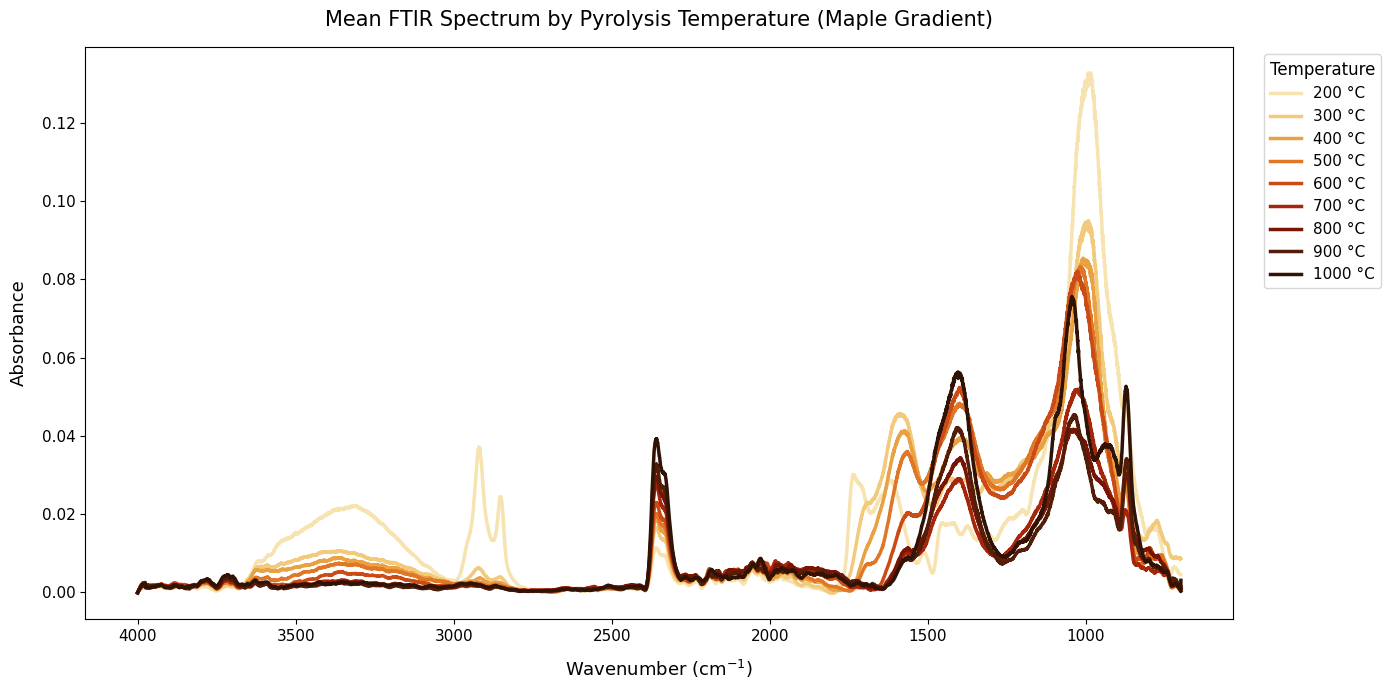

In [12]:
# ==========================================================
# PART 14. Mean FTIR Spectrum for Each Temperature
# ==========================================================

plt.figure(figsize=(14,7))

temps = sorted(df['temp'].unique())
# Distinct 9-color maple/autumn transition palette
maple_9_colors = ['#f7e3af', '#f3ca7b', '#e8a143', '#df7726', '#cb4b16', '#a5260a', '#781505', '#521d09', '#301305']

for idx, temp in enumerate(temps):
    subset = df[df['temp']==temp]
    mean_spec = subset[ftir_cols].mean(axis=0)

    plt.plot(
        wavenumbers,
        mean_spec,
        linewidth=2.5,
        label=f"{temp} °C",
        color=maple_9_colors[idx]
    )

plt.gca().invert_xaxis()

plt.xlabel("Wavenumber (cm$^{-1}$)", fontsize=13, labelpad=10)
plt.ylabel("Absorbance", fontsize=13, labelpad=10)
plt.title("Mean FTIR Spectrum by Pyrolysis Temperature (Maple Gradient)", fontsize=15, pad=15)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    fontsize=11,
    title="Temperature",
    title_fontsize=12
)

plt.tight_layout()
plt.show()

Peak variables: 11


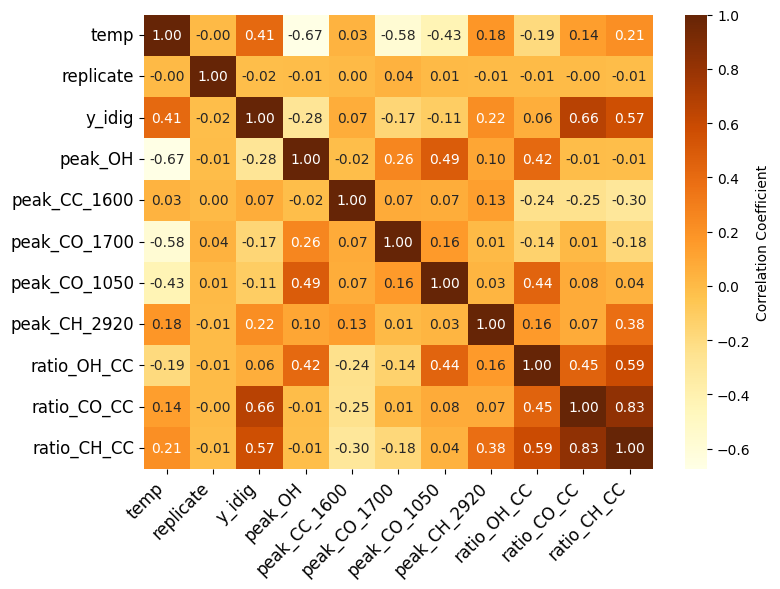

In [13]:
# ==========================================================
# PART 15. Correlation Matrix of Peak Features
# ==========================================================

exclude = ['Biomass','Temperature','ID/IG','Graphitic']
peak_features = []

for col in df.columns:
    if col in exclude:
        continue
    if col in ftir_cols:
        continue
    if pd.api.types.is_numeric_dtype(df[col]):
        peak_features.append(col)

print(f"Peak variables: {len(peak_features)}")

corr = df[peak_features].corr()

plt.figure(figsize=(8,6))

# Using a custom warm maple-themed sequential/diverging color map
sns.heatmap(
    corr,
    cmap='YlOrBr',
    annot=True,
    fmt=".2f",
    annot_kws={'size': 10},
    cbar_kws={'label': 'Correlation Coefficient'}
)

plt.xticks(rotation=45, ha='right', fontsize=12)
plt.yticks(fontsize=12)
plt.tight_layout()
plt.show()

In [14]:
# ==========================================================
# PART 16. PCA of FTIR Spectrum
# ==========================================================

X = df[ftir_cols]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2, random_state=42)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    "PC1":X_pca[:,0],
    "PC2":X_pca[:,1],
    "Biomass":df["biomass"],
    "Temperature":df["temp"]
})

print(
    f"Explained variance : "
    f"{pca.explained_variance_ratio_[0]*100:.2f}% , "
    f"{pca.explained_variance_ratio_[1]*100:.2f}%"
)

Explained variance : 28.54% , 16.31%


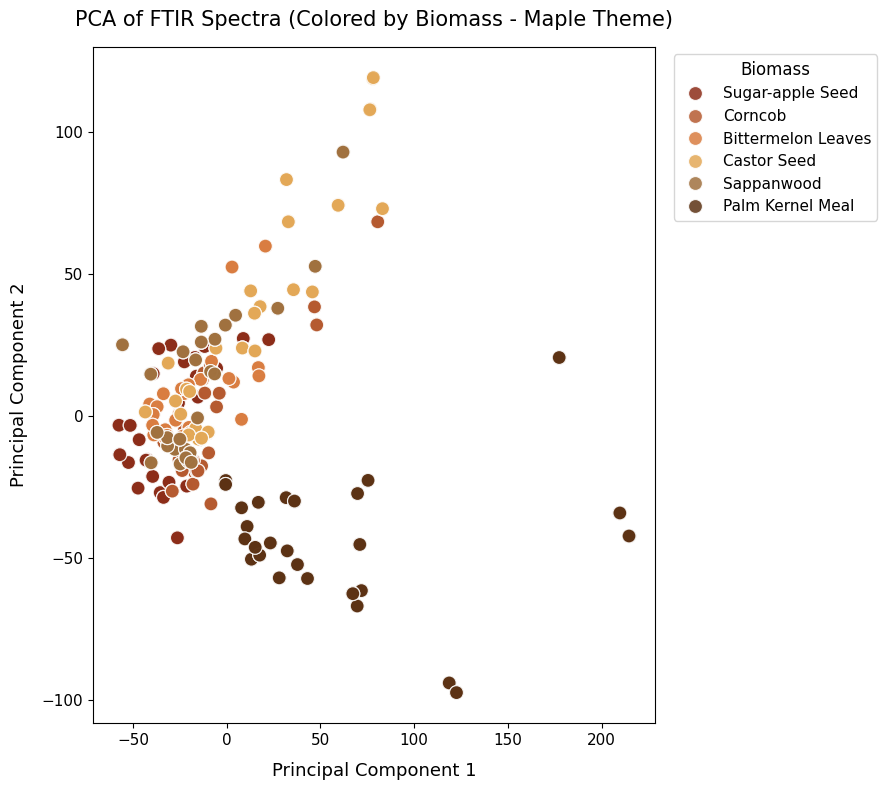

In [15]:
plt.figure(figsize=(9,8))

# Custom maple theme palette for 6 biomass types
maple_biomass_palette = ['#8c2d19', '#b55a30', '#d97d41', '#e3a857', '#a0713f', '#5c3214']

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Biomass",
    palette=maple_biomass_palette,
    s=100,
    alpha=0.85
)

plt.xlabel("Principal Component 1", fontsize=13, labelpad=10)
plt.ylabel("Principal Component 2", fontsize=13, labelpad=10)
plt.title("PCA of FTIR Spectra (Colored by Biomass - Maple Theme)", fontsize=15, pad=15)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    fontsize=11,
    title="Biomass",
    title_fontsize=12
)

plt.tight_layout()
plt.show()

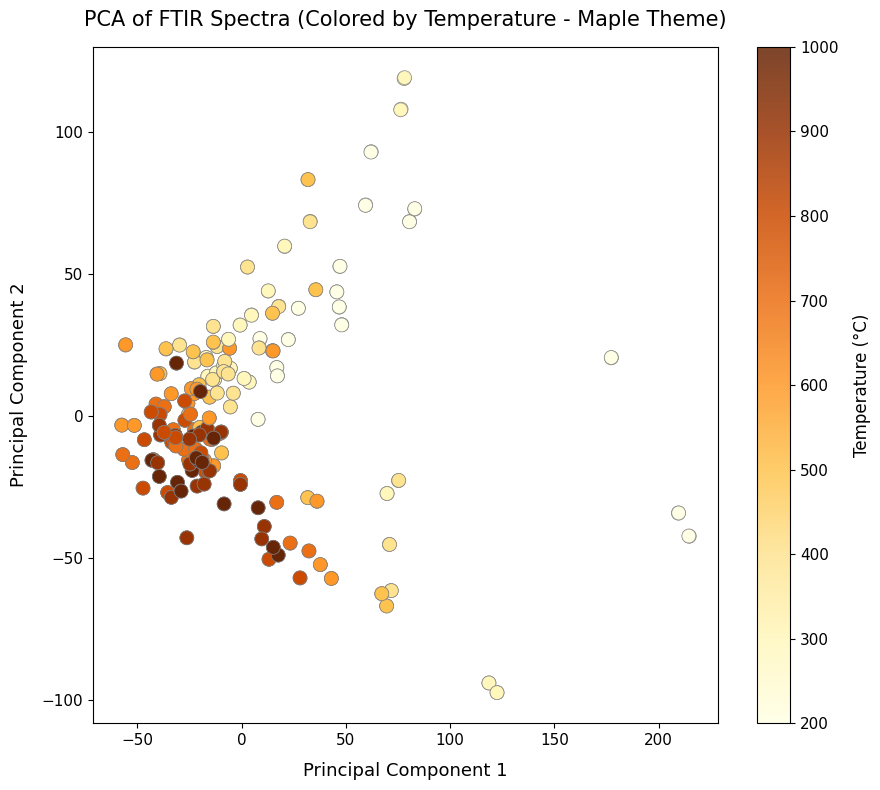

In [16]:
plt.figure(figsize=(9,8))

# Custom continuous-like sequence of maple palette for 9 temperatures
maple_temp_palette = sns.color_palette("YlOrBr", as_cmap=True)

sc = plt.scatter(
    data=pca_df,
    x="PC1",
    y="PC2",
    c="Temperature",
    cmap=maple_temp_palette,
    s=100,
    alpha=0.85,
    edgecolors='grey',
    linewidths=0.5
)

cbar = plt.colorbar(sc)
cbar.set_label("Temperature (°C)", fontsize=12, labelpad=10)
cbar.ax.tick_params(labelsize=11)

plt.xlabel("Principal Component 1", fontsize=13, labelpad=10)
plt.ylabel("Principal Component 2", fontsize=13, labelpad=10)
plt.title("PCA of FTIR Spectra (Colored by Temperature - Maple Theme)", fontsize=15, pad=15)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

plt.tight_layout()
plt.show()

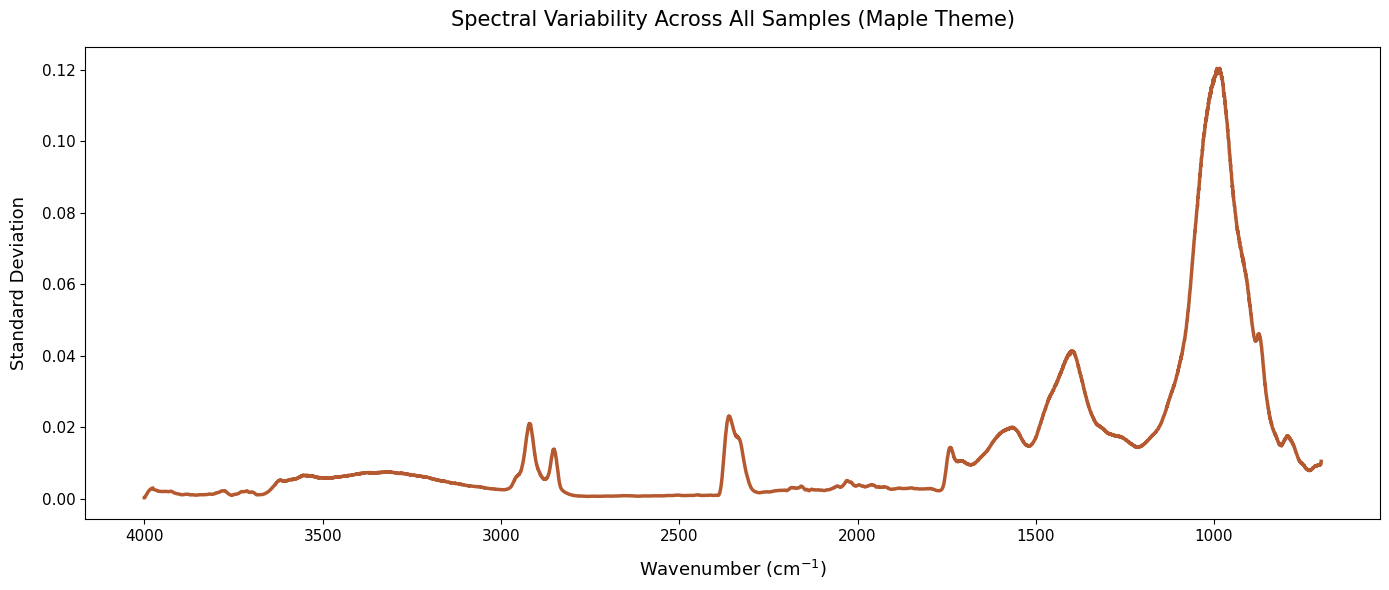

In [17]:
# ==========================================================
# PART 17. Spectral Variability Analysis
# ==========================================================

spectral_std = df[ftir_cols].std(axis=0)

plt.figure(figsize=(14,6))

plt.plot(
    wavenumbers,
    spectral_std,
    linewidth=2.5,
    color='#b55a30' # Distinct maple brown/orange
)

plt.gca().invert_xaxis()

plt.xlabel("Wavenumber (cm$^{-1}$)", fontsize=13, labelpad=10)
plt.ylabel("Standard Deviation", fontsize=13, labelpad=10)
plt.title("Spectral Variability Across All Samples (Maple Theme)", fontsize=15, pad=15)

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

plt.tight_layout()
plt.show()

In [18]:
summary = pd.DataFrame({

    "Number of Samples":[len(df)],
    "Number of Biomass":[df["biomass"].nunique()],
    "Number of Temperatures":[df["temp"].nunique()],
    "Number of FTIR Variables":[len(ftir_cols)],
    "Number of Peak Variables":[len(peak_features)],
    "Mean ID/IG":[df["y_idig"].mean()],
    "Std ID/IG":[df["y_idig"].std()]
})

summary

,Number of Samples,Number of Biomass,Number of Temperatures,Number of FTIR Variables,Number of Peak Variables,Mean ID/IG,Std ID/IG
0,486,6,9,6847,11,1.065465,0.159867
